In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
from src import config as C

# 06 - Explainability (linear contributions + LIME)
Attributions describe what the *model* used; they are **not causal evidence** about why a message is a scam. Run: `python -m src.explainability`.

In [2]:
ex = pd.read_csv(C.TABLES_DIR / 'explain_examples.csv')
display(ex[['model_id','outcome','language','true_label','predicted_label','p_scam','linear_top_features','lime_top_features']])

,model_id,outcome,language,true_label,predicted_label,p_scam,linear_top_features,lime_top_features
0,word_lr,TP,English,Scam,Scam,0.999525,free:+0.778; reply:+0.598; stop:+0.563; 2:+0.537; to:+0.503; 1:+0.447; per:+...,STOP:+0.018; £1.50:+0.017; your:+0.014; FREE:+0.014; per:+0.011; with:+0.011...
1,word_lr,TN,English,Legitimate,Legitimate,0.000834,my:-0.765; i:-0.630; me:-0.513; work:-0.442; do:-0.262; when:-0.246; my work...,me:-0.002; i:-0.002; my:-0.001; when:-0.001; tomorrow:-0.000; work:-0.000; d...
2,word_lr,FP,Mixed/Code-Switched,Legitimate,Scam,0.602735,ka:+0.887; 1:+0.871; apka:+0.616; due:+0.390; se:+0.363; dear:-0.251; date:+...,ka:+0.201; 1:+0.197; apka:+0.156; Dear:-0.104; Lakh:-0.096; se:+0.082; PKR:-...
3,word_lr,FN,English,Scam,Legitimate,0.012315,i:-1.063; call:+0.931; your call:-0.750; your:+0.450; you have:+0.416; when:...,I:-0.033; I'm:-0.033; call:+0.028; when:-0.020; Sorry:-0.018; your:-0.015; m...
4,char_lr,TP,English,Scam,Scam,0.999997,tone:+0.400; 1:+0.358; 0:+0.295; 08:+0.272; 2:+0.263; 0 :+0.253; ton:+0.2...,FREE:+0.015; STOP:+0.014; £1.50:+0.014; RINGTONE:+0.014; with:+0.012; 084528...
5,char_lr,TN,English,Legitimate,Legitimate,0.000011,my :-0.300; my:-0.294; my :-0.294; my:-0.253; me:-0.248; .:-0.246; i :-...,my:-0.000; when:-0.000; me:-0.000; .:-0.000; i:-0.000; tomorrow:-0.000; do:-...
6,char_lr,FP,English,Legitimate,Scam,0.555195,free:+0.511; ree:+0.492; fre:+0.459; free:+0.437; fre:+0.399; me :-0.354;...,free:+0.503; call:+0.284; me:-0.233; pa.:-0.182; Now:+0.062; am:-0.040
7,char_lr,FN,English,Scam,Legitimate,0.004154,i :-0.471; i :-0.361; xt:+0.360; xt :+0.285; 6 :+0.253; 46:+0.246; i:-0.22...,i:-0.010; next:+0.007; do:-0.007; Money:-0.006; 946:+0.005; number:+0.004; w...


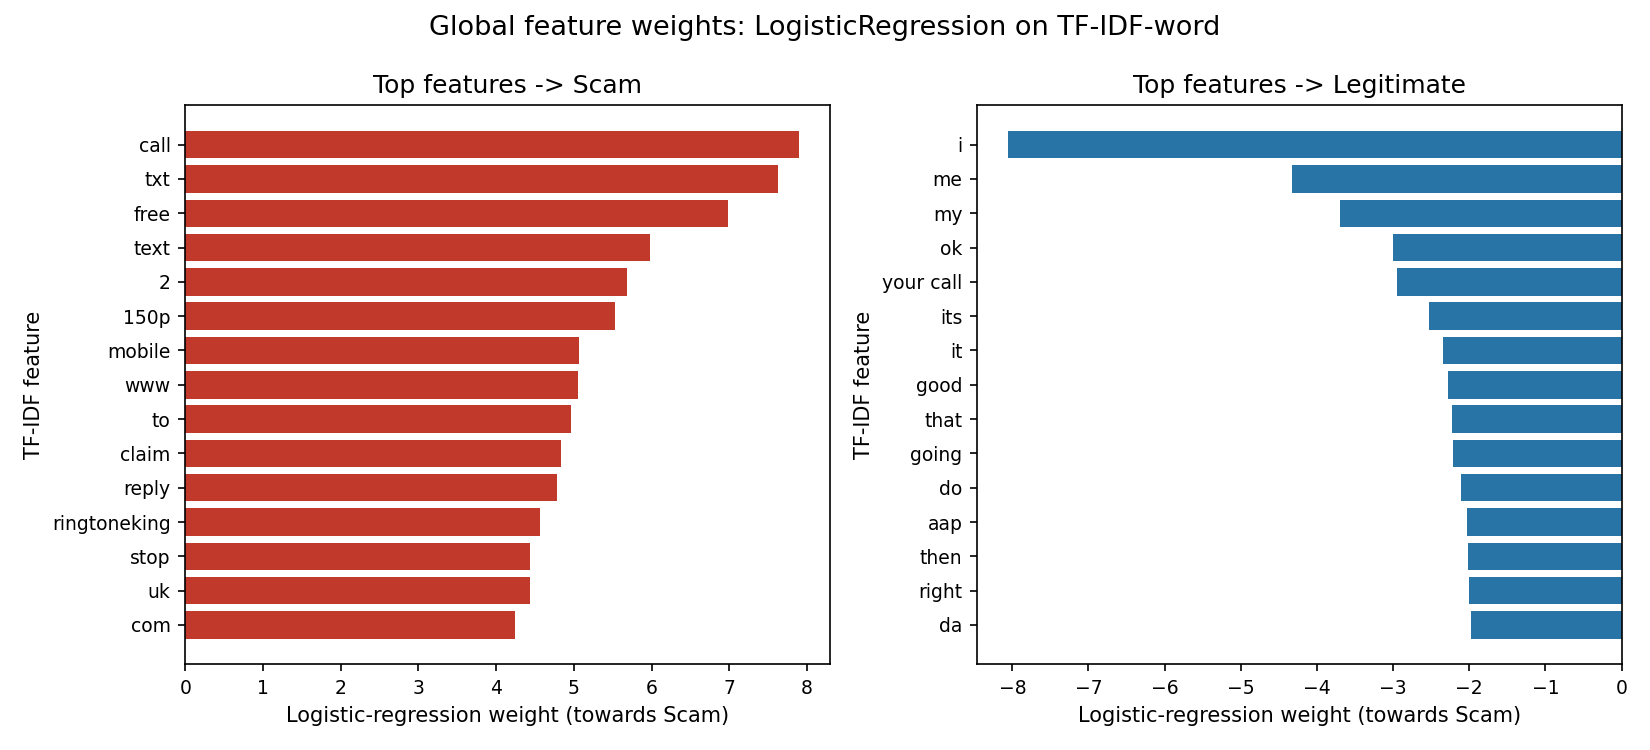

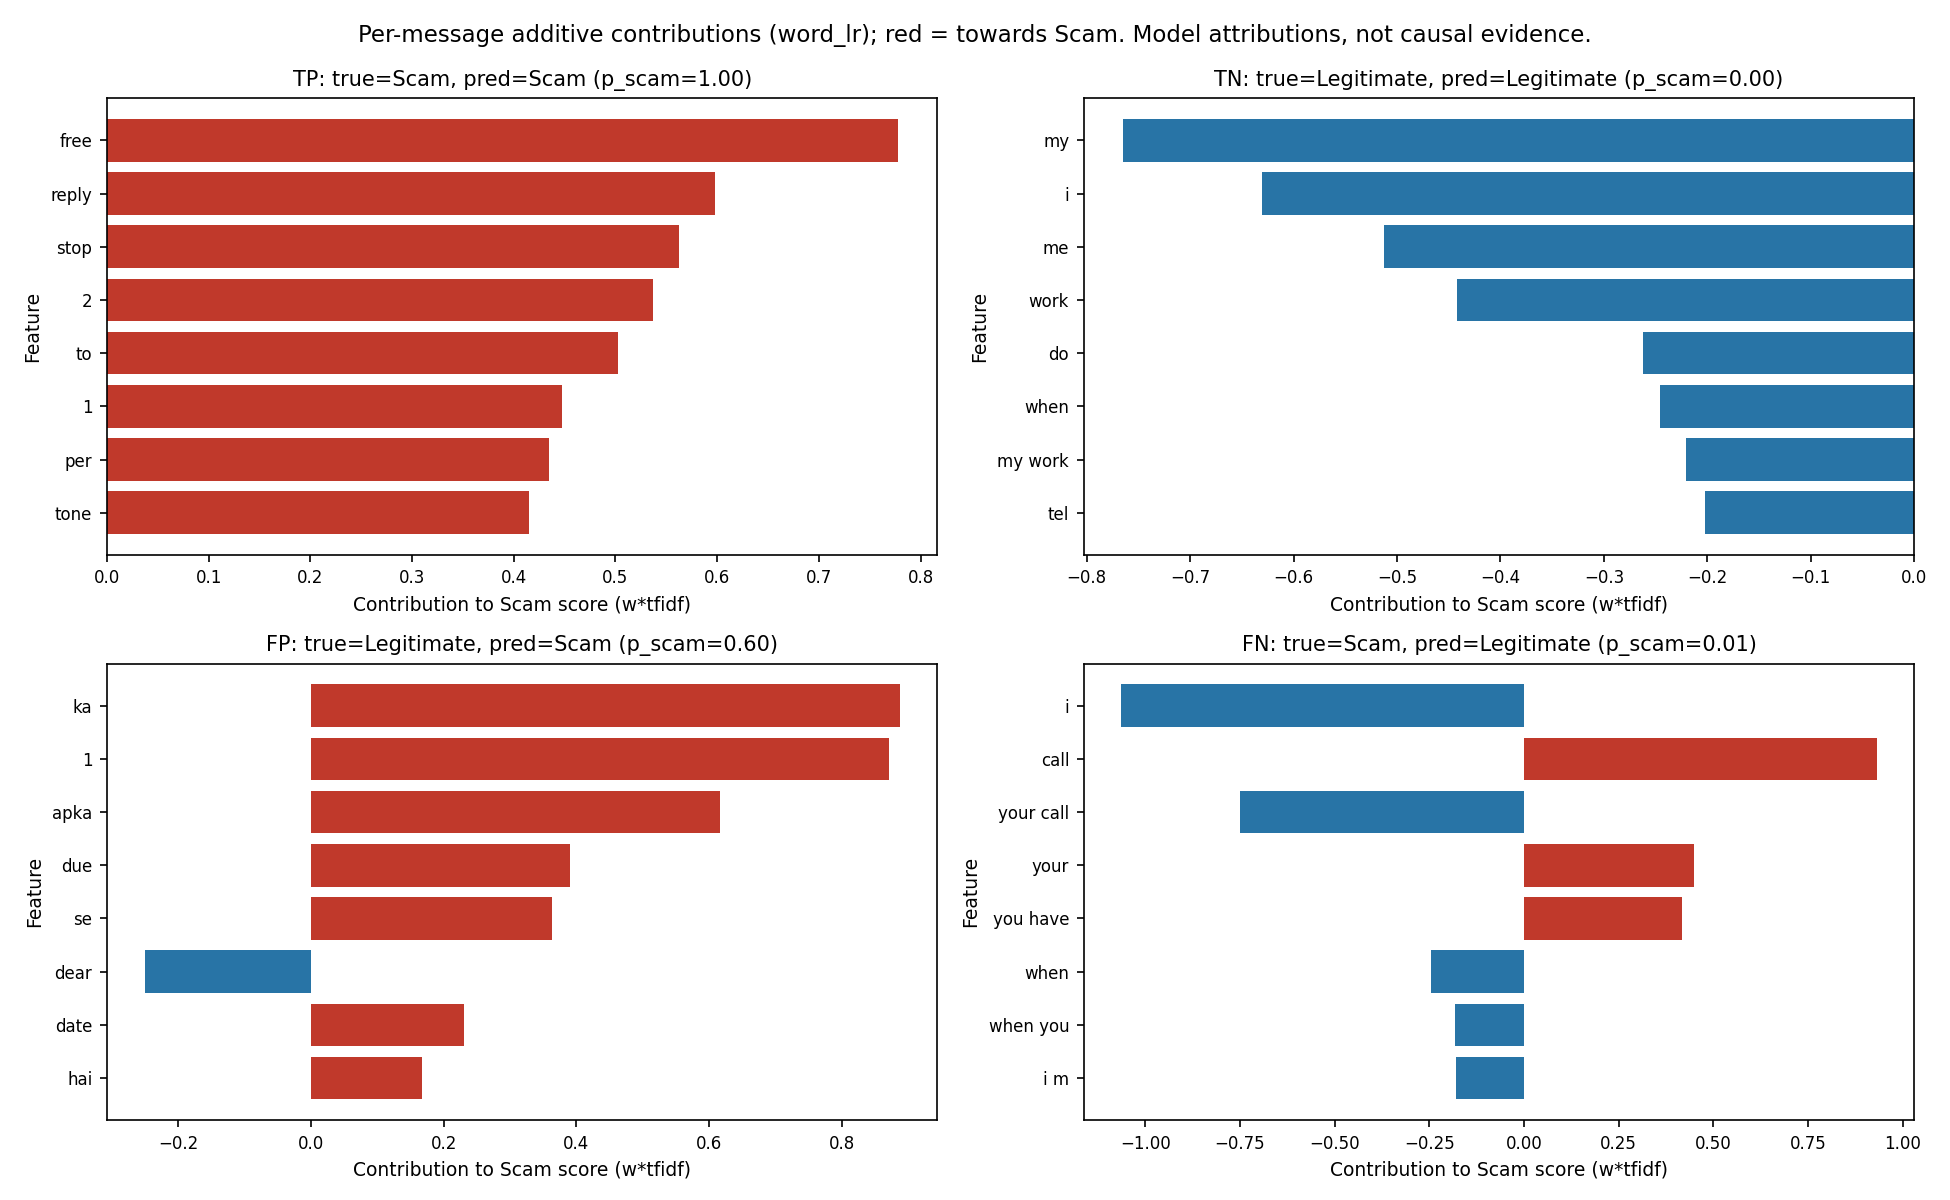

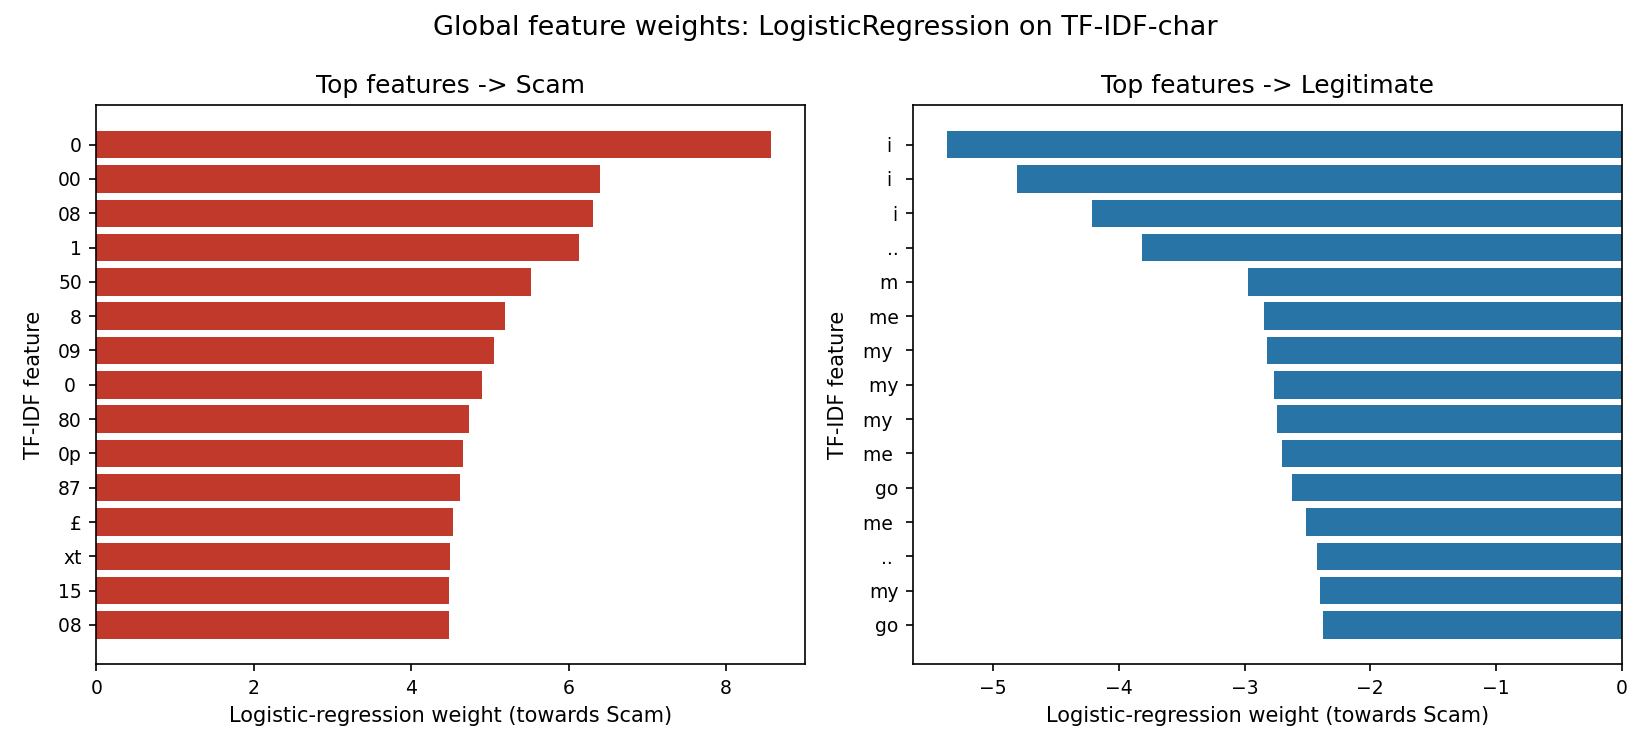

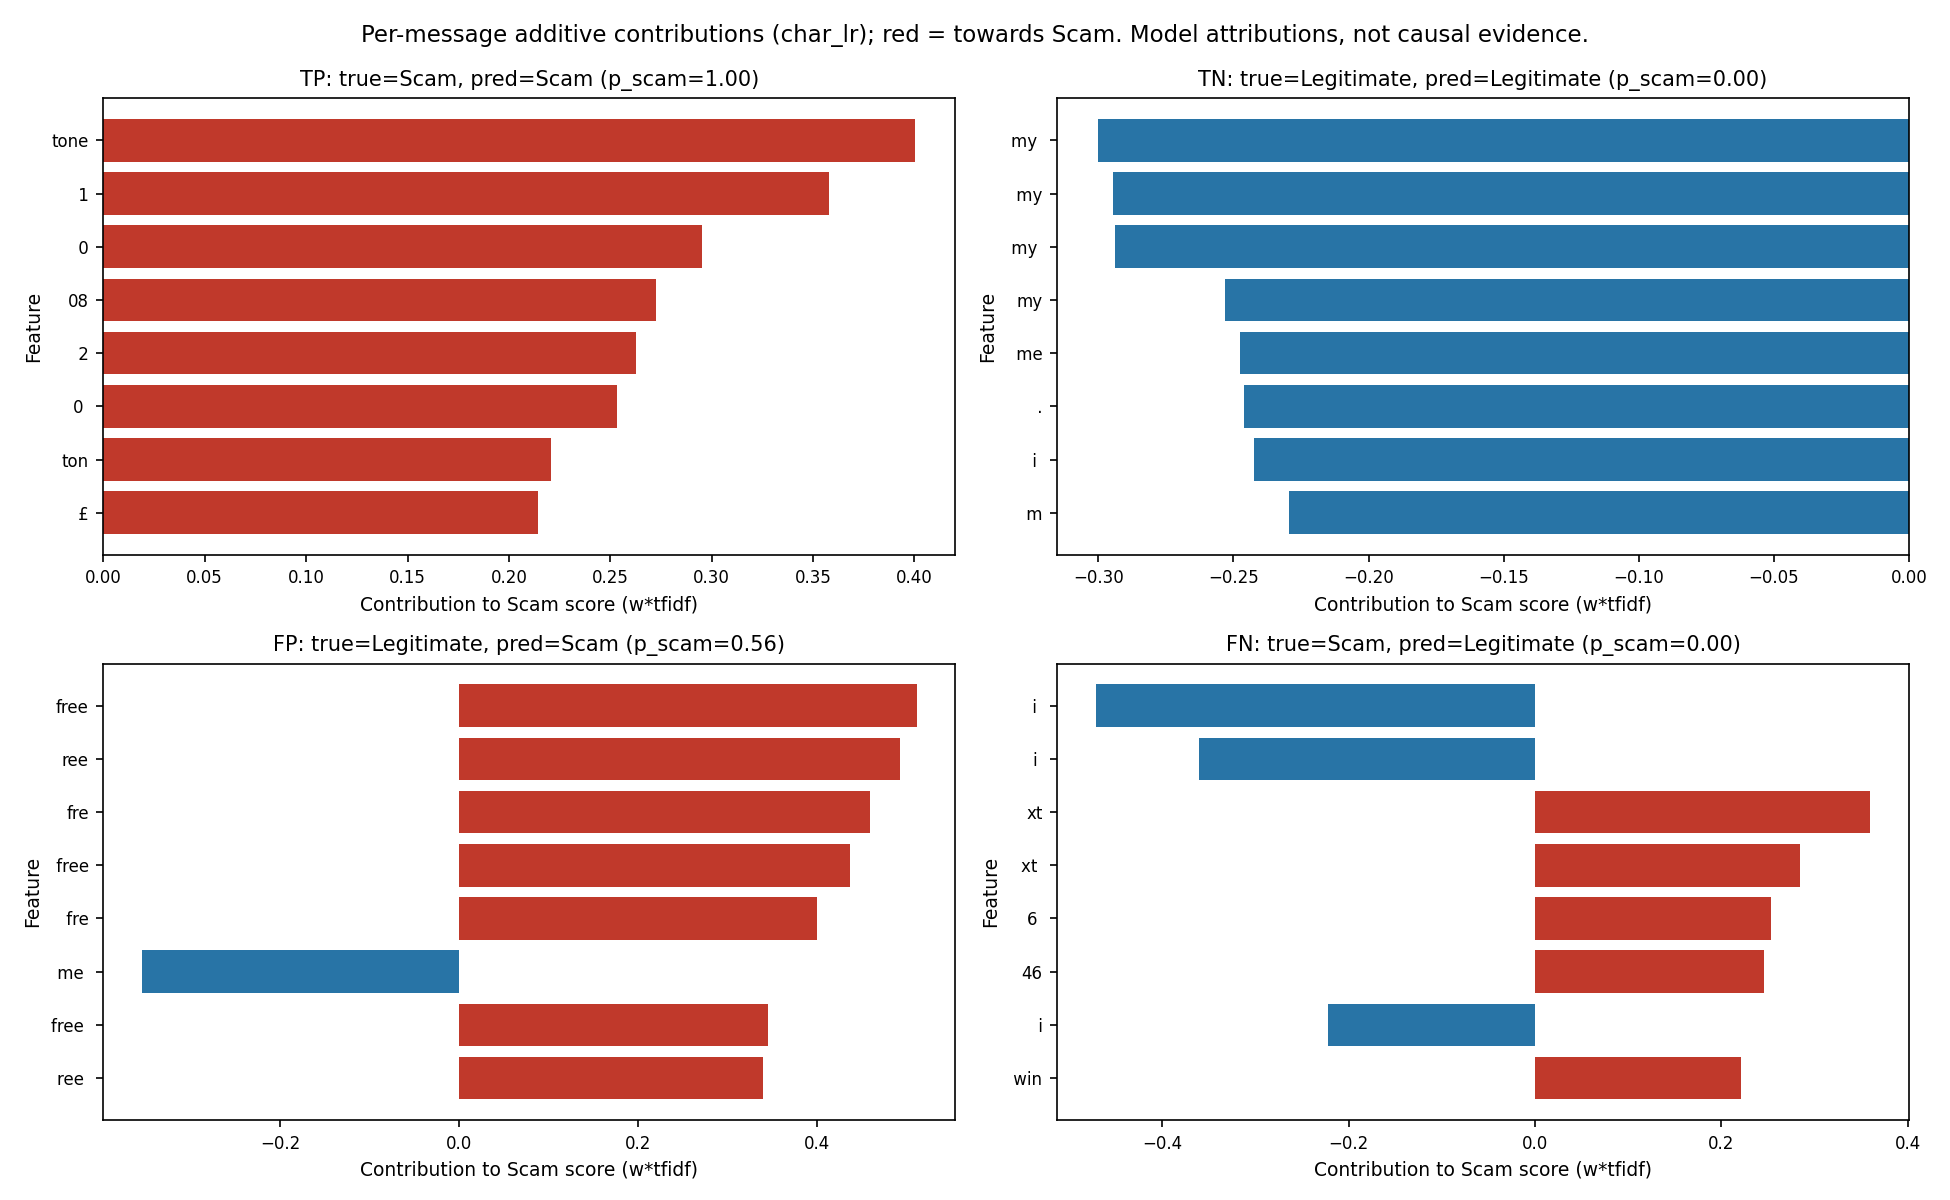

In [3]:
for f in ['explain_global_word_lr','explain_examples_word_lr','explain_global_char_lr','explain_examples_char_lr']:
    display(Image(str(C.FIGURES_DIR / f'{f}.png'), width=800))